In [1]:
import pandas as pd
import numpy as np

In [2]:
from pathlib import Path

In [3]:
DATA_DIR = "data/processed/"
daily_data = pd.read_csv(
    DATA_DIR + "canada_integrated_daily_macro_features_demo2.csv",
    parse_dates=[
        "Date",
        "Bank_Availability_Date",
        "Macro_Reference_Date",
        "Macro_Availability_Date"
    ]
)

daily_data = daily_data.sort_values(
    ["Ticker", "Date"]
).reset_index(drop=True)

print("Shape:", daily_data.shape)
print("Tickers:", daily_data["Ticker"].nunique())
print("Date Range:", daily_data["Date"].min(), "to", daily_data["Date"].max())

daily_data.head()

Shape: (63574, 68)
Tickers: 10
Date Range: 2000-01-04 00:00:00 to 2026-11-06 00:00:00


,Date,Ticker,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits,...,Close_MA_Ratio_10,Close_MA_Ratio_20,Close_MA_Ratio_50,Close_Momentum_5D,Close_Momentum_10D,Close_Momentum_20D,Close_RSI_14,MACD_Pct,MACD_Signal_Pct,MACD_Histogram_Pct
0,2000-01-04,ABX.TO,25.150000,25.65,24.950001,25.450001,17.804482,926500,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2000-01-05,ABX.TO,25.400000,26.00,25.350000,25.650000,17.944401,1452200,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2000-01-06,ABX.TO,25.799999,26.00,25.500000,25.799999,18.049345,600200,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2000-01-07,ABX.TO,25.850000,26.00,25.100000,25.250000,17.664574,1020800,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2000-01-10,ABX.TO,25.350000,25.35,25.150000,25.250000,17.664574,1281100,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# EDA: Dataset Structure & Coverage.

In [4]:
# Dataset dimensions
print(f"Number of Rows: {daily_data.shape[0]:,}")
print(f"Number of Columns: {daily_data.shape[1]}")
print(f"Number of Stocks: {daily_data['Ticker'].nunique()}")
print(f"Unique Trading Dates: {daily_data['Date'].nunique():,}")

print(
    f"Date Range: {daily_data['Date'].min().date()} "
    f"to {daily_data['Date'].max().date()}"
)

Number of Rows: 63,574
Number of Columns: 68
Number of Stocks: 10
Unique Trading Dates: 6,744
Date Range: 2000-01-04 to 2026-11-06


In [5]:
dtype_summary = (
    daily_data.dtypes.astype(str)
    .value_counts()
    .rename_axis("Data Type")
    .reset_index(name="Number of Columns")
)

display(dtype_summary)

,Data Type,Number of Columns
0,float64,58
1,datetime64[us],4
2,int64,4
3,str,2


# Stock Coverage Analysis

In [6]:
stock_coverage = (
    daily_data.groupby("Ticker")
    .agg(
        Records=("Date", "count"),
        First_Date=("Date", "min"),
        Last_Date=("Date", "max"),
        Trading_Days=("Date", "nunique")
    )
    .sort_values("Records", ascending=False)
)

display(stock_coverage)

,Records,First_Date,Last_Date,Trading_Days
Ticker,,,,
ABX.TO,6744,2000-01-04,2026-11-06,6744
BMO.TO,6744,2000-01-04,2026-11-06,6744
BN.TO,6744,2000-01-04,2026-11-06,6744
CNQ.TO,6744,2000-01-04,2026-11-06,6744
CNR.TO,6744,2000-01-04,2026-11-06,6744
ENB.TO,6744,2000-01-04,2026-11-06,6744
RY.TO,6744,2000-01-04,2026-11-06,6744
SU.TO,6744,2000-01-04,2026-11-06,6744
TD.TO,6744,2000-01-04,2026-11-06,6744


# Data Integrity

In [7]:
print("Duplicate Rows:", daily_data.duplicated().sum())

print(
    "Duplicate Date-Ticker:",
    daily_data.duplicated(
        subset=["Date", "Ticker"]
    ).sum()
)

print("Missing Dates:", daily_data["Date"].isna().sum())
print("Missing Tickers:", daily_data["Ticker"].isna().sum())

Duplicate Rows: 0
Duplicate Date-Ticker: 0
Missing Dates: 0
Missing Tickers: 0


# Missing Values Overview

In [8]:
missing_summary = pd.DataFrame({
    "Missing_Count": daily_data.isna().sum(),
    "Missing_Percentage": (
        daily_data.isna().mean() * 100
    )
})

missing_summary = (
    missing_summary[missing_summary["Missing_Count"] > 0]
    .sort_values("Missing_Percentage", ascending=False)
)

display(missing_summary)

,Missing_Count,Missing_Percentage
USD_CAD_Change_21D,39324,61.855476
USD_CAD,38984,61.320666
Policy_Rate_Change_21D,21320,33.535722
Yield_Spread,21294,33.494825
Policy_Rate,21090,33.173939
Bond_Yield_10Y,2473,3.889955
Bank_Availability_Date,2259,3.553339
Close_MA_Ratio_50,490,0.770755
MACD_Histogram_Pct,330,0.519080
MACD_Signal_Pct,330,0.519080


# Stock Price Trends

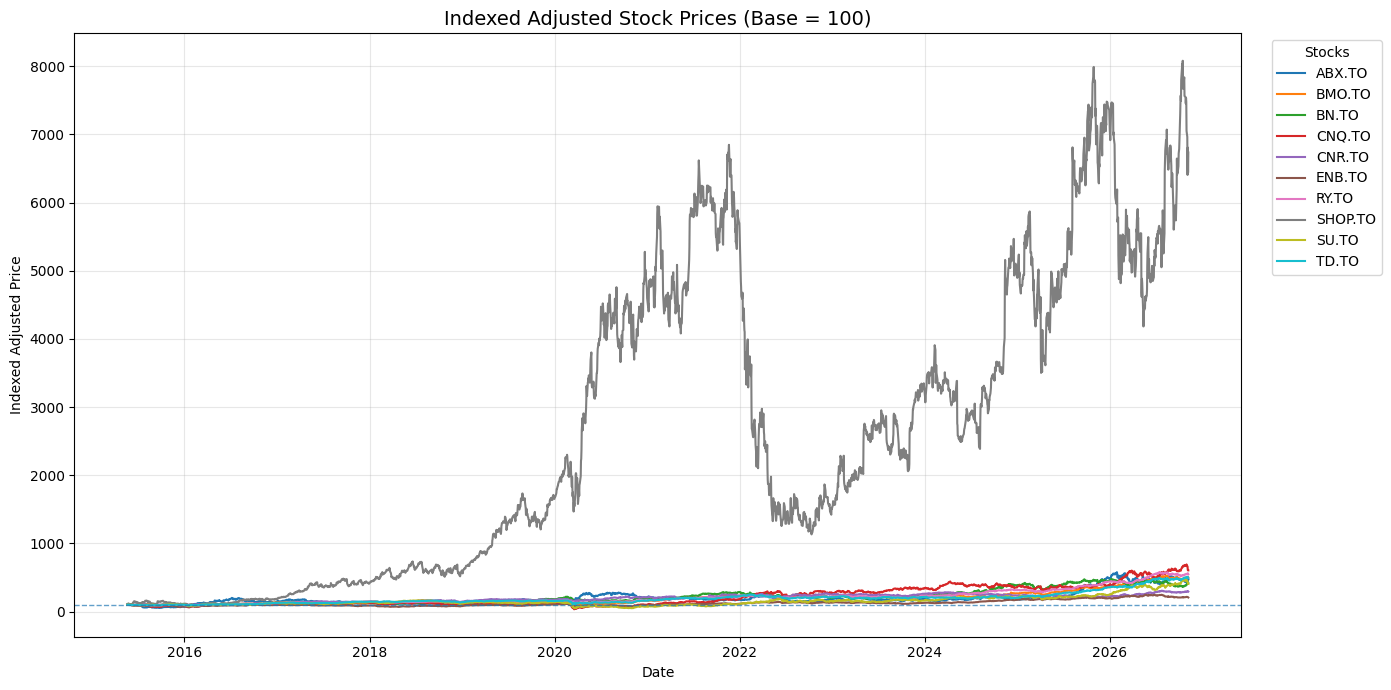

In [9]:
import matplotlib.pyplot as plt

# Common period for all 10 stocks
common_start = daily_data.loc[
    daily_data["Ticker"] == "SHOP.TO", "Date"
].min()

price_data = daily_data.loc[
    daily_data["Date"] >= common_start,
    ["Date", "Ticker", "Adj Close"]
].copy()

price_data = price_data.dropna(subset=["Adj Close"])

price_data = price_data.sort_values(
    ["Ticker", "Date"]
)

# Normalize adjusted prices to 100
price_data["Indexed_Price"] = (
    price_data.groupby("Ticker")["Adj Close"]
    .transform(lambda x: x / x.iloc[0] * 100)
)

# Pivot for plotting
price_pivot = price_data.pivot(
    index="Date",
    columns="Ticker",
    values="Indexed_Price"
)

# Plot
plt.figure(figsize=(14, 7))

for ticker in price_pivot.columns:
    plt.plot(
        price_pivot.index,
        price_pivot[ticker],
        label=ticker,
        linewidth=1.5
    )

plt.axhline(
    y=100,
    linestyle="--",
    linewidth=1,
    alpha=0.7
)

plt.title(
    "Indexed Adjusted Stock Prices (Base = 100)",
    fontsize=14
)

plt.xlabel("Date")
plt.ylabel("Indexed Adjusted Price")
plt.legend(
    title="Stocks",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Indexed Adjusted Stock Prices

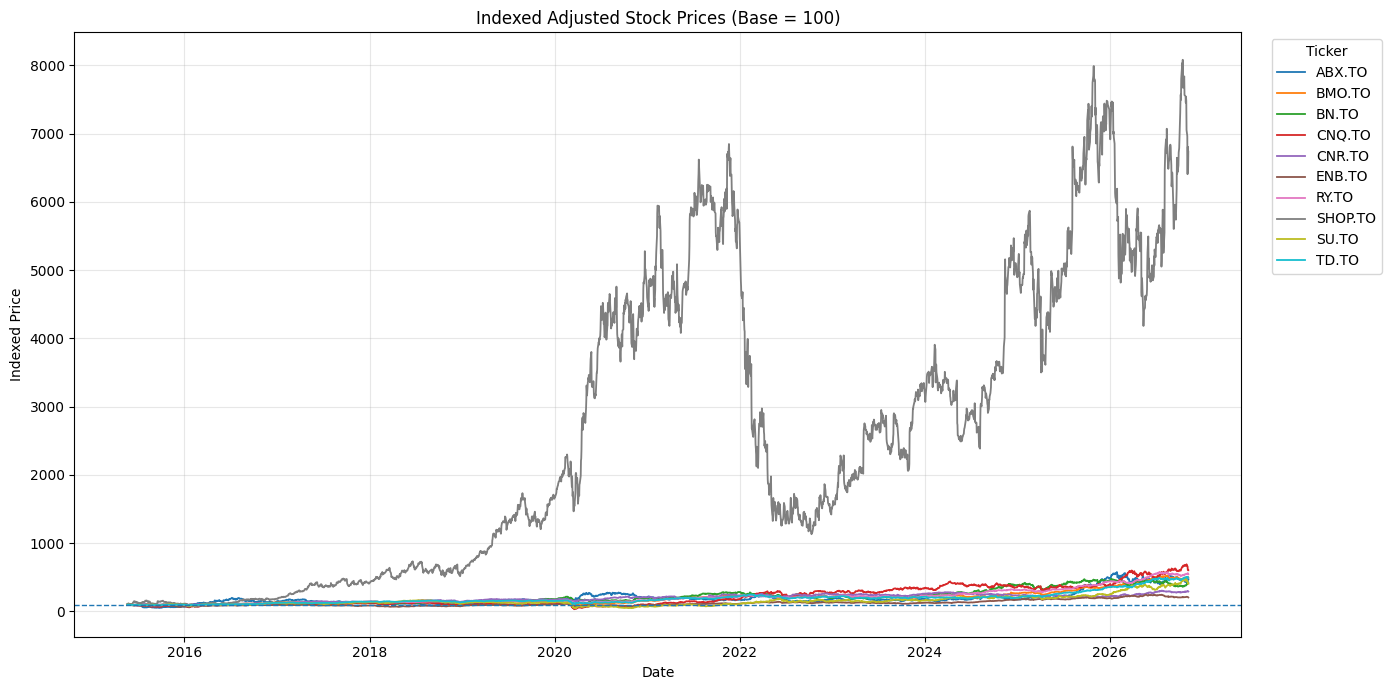

In [10]:
import matplotlib.pyplot as plt

# Define common analysis period
common_start = pd.Timestamp("2015-05-21")

price_data = daily_data.loc[
    daily_data["Date"] >= common_start,
    ["Date", "Ticker", "Adj Close"]
].copy()

price_data = price_data.sort_values(["Ticker", "Date"])

# Normalize prices to a common base of 100
price_data["Indexed_Price"] = (
    price_data.groupby("Ticker")["Adj Close"]
    .transform(lambda x: (x / x.iloc[0]) * 100)
)

# Reshape data for visualization
price_pivot = price_data.pivot(
    index="Date",
    columns="Ticker",
    values="Indexed_Price"
)

# Plot
plt.figure(figsize=(14, 7))

for ticker in price_pivot.columns:
    plt.plot(
        price_pivot.index,
        price_pivot[ticker],
        label=ticker,
        linewidth=1.3
    )

plt.axhline(100, linestyle="--", linewidth=1)

plt.title("Indexed Adjusted Stock Prices (Base = 100)")
plt.xlabel("Date")
plt.ylabel("Indexed Price")
plt.legend(title="Ticker", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
stock_performance = (
    price_data.groupby("Ticker")
    .agg(
        Initial_Price=("Indexed_Price", "first"),
        Final_Price=("Indexed_Price", "last"),
        Observations=("Date", "count")
    )
)

stock_performance["Total_Return_%"] = (
    stock_performance["Final_Price"] - 100
)

stock_performance = stock_performance.sort_values(
    "Total_Return_%",
    ascending=False
)

display(stock_performance.round(2))

,Initial_Price,Final_Price,Observations,Total_Return_%
Ticker,,,,
SHOP.TO,100.0,6735.04,2878,6635.04
CNQ.TO,100.0,603.79,2878,503.79
RY.TO,100.0,546.17,2878,446.17
BMO.TO,100.0,496.27,2878,396.27
TD.TO,100.0,491.35,2878,391.35
ABX.TO,100.0,467.29,2878,367.29
BN.TO,100.0,415.55,2878,315.55
SU.TO,100.0,406.70,2878,306.70
CNR.TO,100.0,292.90,2878,192.90


### Stock Price Analysis

The indexed adjusted price analysis compares the historical performance of ten Canadian stocks over a common period from May 21, 2015, to November 6, 2026.

All stocks were normalized to a base value of 100 to make their relative performance comparable.

Key findings:

- SHOP.TO achieved the highest cumulative return, reaching an indexed value of 6,735.04.
- CNQ.TO ranked second, with a cumulative return of 503.79%.
- RY.TO, BMO.TO, and TD.TO showed relatively similar cumulative performance.
- ENB.TO recorded the lowest cumulative return among the selected stocks, at 105.97%.

The results highlight substantial differences in long-term stock performance. They also demonstrate why ticker-level information should be retained during subsequent analysis and modeling.

These historical results are descriptive and do not imply that past performance will continue in the future.

# Future Return Distribution

In [12]:
target = daily_data["Future_Return_5D"].dropna()

# Descriptive statistics
display(
    target.describe().to_frame("Future_Return_5D")
)

print("Positive Returns:", (target > 0).sum())
print("Negative Returns:", (target < 0).sum())
print("Zero Returns:", (target == 0).sum())

print("Skewness:", target.skew())
print("Kurtosis:", target.kurtosis())

,Future_Return_5D
count,63524.000000
mean,0.362051
std,4.238297
min,-47.013487
25%,-1.666637
50%,0.373576
75%,2.314759
max,43.282065


Positive Returns: 35081
Negative Returns: 28240
Zero Returns: 203
Skewness: 0.18333189743929798
Kurtosis: 8.92808866380564


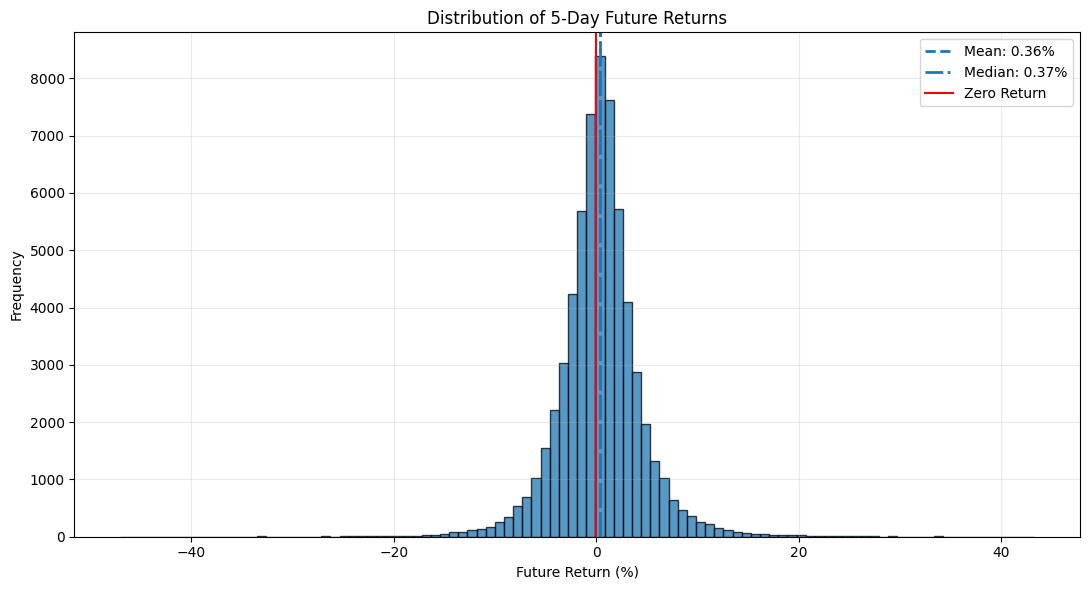

In [13]:
plt.figure(figsize=(11, 6))

plt.hist(
    target,
    bins=100,
    edgecolor="black",
    alpha=0.75
)

plt.axvline(
    target.mean(),
    linestyle="--",
    linewidth=2,
    label=f"Mean: {target.mean():.2f}%"
)

plt.axvline(
    target.median(),
    linestyle="-.",
    linewidth=2,
    label=f"Median: {target.median():.2f}%"
)

plt.axvline(
    0,
    color="red",
    linewidth=1.5,
    label="Zero Return"
)

plt.title("Distribution of 5-Day Future Returns")
plt.xlabel("Future Return (%)")
plt.ylabel("Frequency")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Future Return Distribution Analysis

The target variable, `Future_Return_5D`, represents the percentage return over the next five trading days.

The dataset contains 63,524 valid target observations:

- Positive returns: 35,081 (55.22%).
- Negative returns: 28,240 (44.45%).
- Zero returns: 203 (0.32%).

The target distribution has a slightly positive skewness of 0.1833, indicating a mild asymmetry toward positive returns.

The kurtosis is 8.9281, suggesting heavy tails and the presence of extreme return observations compared with a normal distribution.

These findings indicate that five-day stock returns exhibit substantial variability and extreme movements. Therefore, outliers should be investigated carefully, and normality should not be assumed when selecting evaluation methods or interpreting model performance.

# Correlation Heatmap

In [14]:
raw_stock_columns = [
    "Open", "High", "Low", "Close",
    "Adj Close", "Volume",
    "Dividends", "Stock Splits"
]

In [15]:
metadata_columns = [
    "Date",
    "Ticker",
    "Bank_Availability_Date",
    "Macro_Reference_Date",
    "Macro_Availability_Date",
    "Macro_Feature_Availability_Date"
]

In [30]:
# Economic indicators
ECONOMIC = [
    "Policy_Rate",
    "Bond_Yield_10Y",
    "USD_CAD",
    "CPI",
    "Inflation_YoY",
    "GDP_Real_Millions_CAD",
    "GDP_MoM",
    "GDP_YoY",
    "Employment",
    "Labour_Force",
    "Participation_Rate",
    "Unemployment_Rate",
    "BCPI_Total",
    "BCPI_NonEnergy",
    "BCPI_Energy",
    "BCPI_Metals",
    "BCPI_Forestry",
    "BCPI_Agriculture",
    "BCPI_Fish",
    "BCPI_Change_12M",
    "BCPI_Energy_Change_12M",
    "BCPI_Metals_Change_12M",
    "Unemployment_Change_12M",
    "Employment_Growth_12M",
    "Yield_Spread",
    "Policy_Rate_Change_21D",
    "USD_CAD_Change_21D"
]

In [31]:
# Cyclical calendar features
CALENDAR = [
    "DayOfWeek_Sin",
    "DayOfWeek_Cos",
    "Month_Sin",
    "Month_Cos"
]

In [32]:
# Technical indicators
TECHNICAL = [
    "Close_Daily_Return",
    "Close_Return_Lag_1",
    "Close_Return_Lag_5",
    "Close_Return_Lag_10",
    "Close_Return_Lag_20",
    "Close_Volatility_5D",
    "Close_Volatility_10D",
    "Close_Volatility_20D",
    "Close_MA_Ratio_5",
    "Close_MA_Ratio_10",
    "Close_MA_Ratio_20",
    "Close_MA_Ratio_50",
    "Close_Momentum_5D",
    "Close_Momentum_10D",
    "Close_Momentum_20D",
    "Close_RSI_14",
    "MACD_Pct",
    "MACD_Signal_Pct",
    "MACD_Histogram_Pct"
]

In [36]:
# Categorical features to be one-hot encoded
DUMMIES = [
    "Ticker"
]

In [42]:
TO_PREDICT = "Future_Return_5D"

In [37]:
NUMERIC = TECHNICAL + ECONOMIC + CALENDAR

FEATURES = NUMERIC + DUMMIES

In [19]:
target_column = "Future_Return_5D"

In [43]:
NUMERIC = (
    TECHNICAL
    + ECONOMIC
    + CALENDAR 
)

correlation = (
    daily_data[NUMERIC + [TO_PREDICT]]
    .corr(numeric_only=True)[TO_PREDICT]
    .drop(TO_PREDICT)
    .sort_values(key=abs, ascending=False)
)

display(
    correlation.to_frame("Correlation with Future_Return_5D")
)

,Correlation with Future_Return_5D
MACD_Pct,-0.074849
MACD_Signal_Pct,-0.066986
Close_MA_Ratio_20,-0.066015
Close_MA_Ratio_50,-0.060502
Close_Momentum_20D,-0.053717
Close_Momentum_10D,-0.052430
Close_MA_Ratio_10,-0.050333
Policy_Rate_Change_21D,-0.043727
USD_CAD,0.043362
Close_Momentum_5D,-0.042834


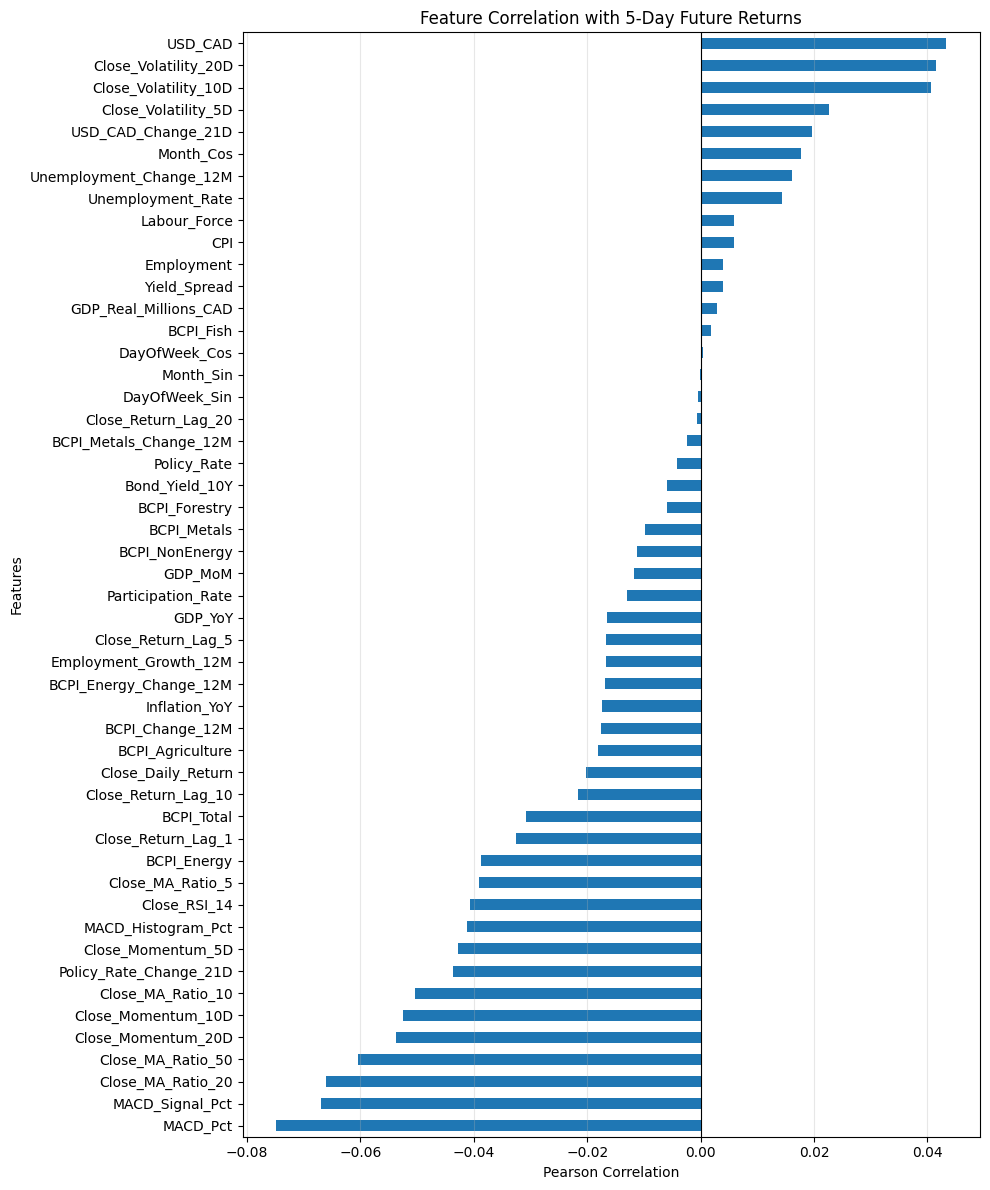

In [21]:
plt.figure(figsize=(10, 12))

correlation.sort_values().plot(
    kind="barh"
)

plt.axvline(0, color="black", linewidth=0.8)

plt.title("Feature Correlation with 5-Day Future Returns")
plt.xlabel("Pearson Correlation")
plt.ylabel("Features")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### Feature Correlation Analysis

Pearson correlation analysis was performed to examine the linear relationships between candidate features and the target variable, `Future_Return_5D`.

The results show that all individual feature correlations with the target are relatively weak.

The strongest correlations were observed among technical indicators:

- `MACD_Pct`: -0.0748
- `MACD_Signal_Pct`: -0.0670
- `Close_MA_Ratio_20`: -0.0660
- `Close_MA_Ratio_50`: -0.0605
- `Close_Momentum_20D`: -0.0537

Economic indicators also showed weak linear relationships. The strongest examples included `Policy_Rate_Change_21D` (-0.0437), `USD_CAD` (0.0434), and `BCPI_Energy` (-0.0387).

Calendar features exhibited correlations close to zero.

Overall, the analysis suggests that no single feature provides a strong linear relationship with five-day future stock returns. However, weak individual correlations do not necessarily imply that these features lack predictive value. Non-linear relationships and interactions between features may still provide useful information.

Therefore, feature selection and model evaluation should consider multivariate relationships and out-of-sample performance rather than relying exclusively on individual correlation values.

# Economic Conditions vs. Future Stock Returns

In [44]:
rregime_labels = [
    "Very Low",
    "Low",
    "Medium",
    "High",
    "Very High"
]

economic_analysis = daily_data[ECONOMIC + [TO_PREDICT]].copy()

for feature in ECONOMIC:

    regimes = pd.qcut(
        economic_analysis[feature],
        q=5,
        duplicates="drop"
    )

    number_of_regimes = len(regimes.cat.categories)
    labels = regime_labels[:number_of_regimes]

    economic_analysis[f"{feature}_Regime"] = (
        regimes.cat.rename_categories(labels)
    )

    print(f"{feature}: {number_of_regimes} regimes")

Policy_Rate: 4 regimes
Bond_Yield_10Y: 5 regimes
USD_CAD: 5 regimes
CPI: 5 regimes
Inflation_YoY: 5 regimes
GDP_Real_Millions_CAD: 5 regimes
GDP_MoM: 5 regimes
GDP_YoY: 5 regimes
Employment: 5 regimes
Labour_Force: 5 regimes
Participation_Rate: 5 regimes
Unemployment_Rate: 5 regimes
BCPI_Total: 5 regimes
BCPI_NonEnergy: 5 regimes
BCPI_Energy: 5 regimes
BCPI_Metals: 5 regimes
BCPI_Forestry: 5 regimes
BCPI_Agriculture: 5 regimes
BCPI_Fish: 5 regimes
BCPI_Change_12M: 5 regimes
BCPI_Energy_Change_12M: 5 regimes
BCPI_Metals_Change_12M: 5 regimes
Unemployment_Change_12M: 5 regimes
Employment_Growth_12M: 5 regimes
Yield_Spread: 5 regimes
Policy_Rate_Change_21D: 2 regimes
USD_CAD_Change_21D: 5 regimes


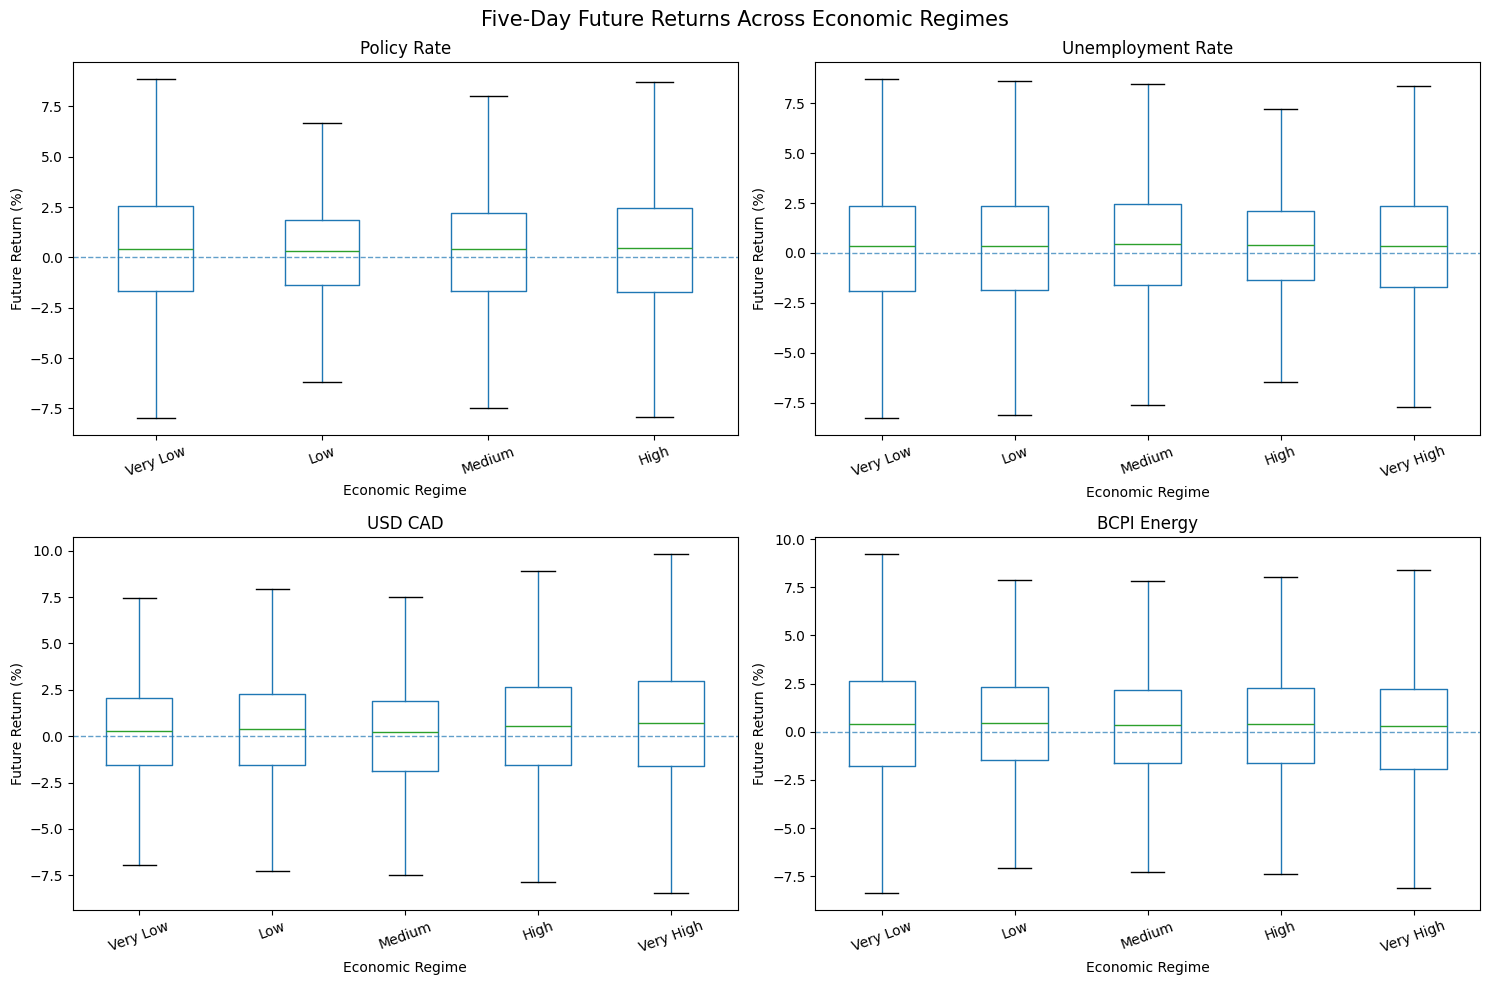

In [45]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

axes = axes.flatten()

for ax, feature in zip(axes, economic_features):

    plot_data = economic_analysis.dropna(
        subset=[f"{feature}_Regime"]
    )

    plot_data.boxplot(
        column="Future_Return_5D",
        by=f"{feature}_Regime",
        ax=ax,
        grid=False,
        showfliers=False
    )

    ax.axhline(
        0,
        linestyle="--",
        linewidth=1,
        alpha=0.7
    )

    ax.set_title(feature.replace("_", " "))
    ax.set_xlabel("Economic Regime")
    ax.set_ylabel("Future Return (%)")

    ax.tick_params(axis="x", rotation=20)

plt.suptitle(
    "Five-Day Future Returns Across Economic Regimes",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [46]:
for feature in ECONOMIC:

    summary = (
        economic_analysis
        .dropna(subset=[f"{feature}_Regime"])
        .groupby(f"{feature}_Regime", observed=True)
        ["Future_Return_5D"]
        .agg(["count", "mean", "median", "std"])
        .round(3)
    )

    print(f"\n{'=' * 55}")
    print(f"Economic Feature: {feature}")
    print("=" * 55)

    display(summary)


Economic Feature: Policy_Rate


,count,mean,median,std
Policy_Rate_Regime,,,,
Very Low,12957,0.586,0.433,4.477
Low,13007,0.261,0.320,3.557
Medium,8200,0.100,0.397,4.479
High,8280,0.471,0.446,4.233



Economic Feature: Bond_Yield_10Y


,count,mean,median,std
Bond_Yield_10Y_Regime,,,,
Very Low,12390,0.477,0.389,4.890
Low,12071,0.227,0.339,3.491
Medium,12276,0.334,0.377,4.526
High,12290,0.414,0.473,4.514
Very High,12034,0.303,0.301,3.445



Economic Feature: USD_CAD


,count,mean,median,std
USD_CAD_Regime,,,,
Very Low,4930,0.247,0.298,4.037
Low,4920,0.357,0.399,4.058
Medium,4930,-0.064,0.213,4.330
High,4920,0.514,0.557,4.398
Very High,4840,0.946,0.712,5.466


... (44 outputs left out)


Economic Feature: Policy_Rate_Change_21D


,count,mean,median,std
Policy_Rate_Change_21D_Regime,,,,
Very Low,38487,0.403,0.414,4.123
Low,3727,-0.082,0.061,4.416



Economic Feature: USD_CAD_Change_21D


,count,mean,median,std
USD_CAD_Change_21D_Regime,,,,
Very Low,4810,0.417,0.444,4.247
Low,4840,0.562,0.594,4.095
Medium,4850,0.319,0.318,3.945
High,4850,0.254,0.375,4.710
Very High,4850,0.458,0.356,5.383


## Economic Regimes and Future Stock Returns

To investigate whether future stock returns vary under different economic conditions, all 27 economic features were divided into quantile-based regimes using `pd.qcut()`. Depending on the distribution and number of unique values, each feature was assigned up to five regimes, ranging from Very Low to Very High.

For each regime, the count, mean, median, and standard deviation of five-day future stock returns were calculated.

### Key Observations

- **Interest Rates and Bond Yields:** Policy rates and 10-year bond yields did not show a consistent directional relationship with future stock returns across their respective regimes. The policy rate produced only four regimes because of repeated quantile boundaries.

- **Exchange Rate (USD/CAD):** The Very High regime recorded the highest average and median future returns (0.946% and 0.712%, respectively). This suggests that periods of a weaker Canadian dollar coincided with higher subsequent returns in the selected stock sample. However, this association does not establish causation.

- **Inflation and Economic Growth:** CPI, inflation, and GDP-related indicators showed varying return patterns across their regimes, without a consistent monotonic relationship. Higher values did not necessarily correspond to higher or lower future returns.

- **Labour Market Indicators:** Employment, labour force, participation rate, and unemployment-related features also displayed mixed patterns. No single directional relationship was consistently observed across all labour market indicators.

- **Commodity Markets:** Several commodity indicators, particularly BCPI Total and BCPI Energy, recorded relatively lower average future returns in their Very High regimes. However, other commodity indicators showed different patterns, indicating that the relationship depends on the commodity category and should not be generalized.

- **Economic Changes and Spreads:** Year-over-year changes in commodity prices, employment, unemployment, and short-term changes in interest rates and exchange rates showed varying results. No consistent relationship across all these features was identified.

### Overall Interpretation

The analysis suggests that economic conditions may be associated with differences in future stock returns, but these relationships are generally weak and inconsistent across the examined indicators.

Although USD/CAD showed a relatively clear pattern, most economic features did not exhibit a stable increasing or decreasing relationship across their regimes.

Furthermore, the standard deviations of future returns were generally much larger than the differences between regime averages, indicating substantial return variability within each economic condition.

These findings should be interpreted as exploratory rather than evidence of statistically significant relationships or profitable trading opportunities.

It is also important to note that macroeconomic observations are shared across multiple stocks on the same dates. Therefore, the reported counts represent stock-date observations rather than independent economic observations.

Finally, the quantile thresholds were calculated using the complete historical dataset for descriptive EDA purposes. They must not be reused directly as predictive thresholds during model training or backtesting. Any thresholds used in predictive experiments must be estimated using training data only.

Further analysis through chronological validation, multivariate modeling, and historical trading simulations will help determine whether these economic features provide additional predictive value.

# Stock Trading Activity: Volume vs. Trading Value

In [27]:
# Common period for all 10 stocks
common_start = daily_data.loc[
    daily_data["Ticker"] == "SHOP.TO", "Date"
].min()

trading_activity = daily_data.loc[
    daily_data["Date"] >= common_start,
    ["Date", "Ticker", "Close", "Volume"]
].copy()

# Calculate approximate daily trading value in CAD
trading_activity["Trading_Value"] = (
    trading_activity["Close"] * trading_activity["Volume"]
)

# Exclude invalid prices and zero-volume observations
trading_activity = trading_activity[
    (trading_activity["Close"] > 0) &
    (trading_activity["Volume"] > 0)
].copy()

In [28]:
trading_summary = (
    trading_activity
    .groupby("Ticker")
    .agg(
        Trading_Days=("Date", "nunique"),
        Mean_Trading_Value=("Trading_Value", "mean"),
        Median_Trading_Value=("Trading_Value", "median"),
        Total_Trading_Value=("Trading_Value", "sum")
    )
    .sort_values("Median_Trading_Value", ascending=False)
)

# Display values in millions of CAD
trading_summary[
    [
        "Mean_Trading_Value",
        "Median_Trading_Value",
        "Total_Trading_Value"
    ]
] /= 1_000_000

display(trading_summary.round(2))

,Trading_Days,Mean_Trading_Value,Median_Trading_Value,Total_Trading_Value
Ticker,,,,
RY.TO,2878,452.68,334.62,1302814.74
TD.TO,2878,422.06,302.55,1214697.51
ENB.TO,2878,328.85,237.93,946426.18
SU.TO,2878,284.13,196.39,817726.82
BMO.TO,2878,256.68,194.90,738729.84
CNQ.TO,2878,346.61,188.80,997544.21
SHOP.TO,2878,190.87,175.68,549313.64
CNR.TO,2877,166.98,140.38,480390.36
ABX.TO,2878,118.93,88.29,342272.40


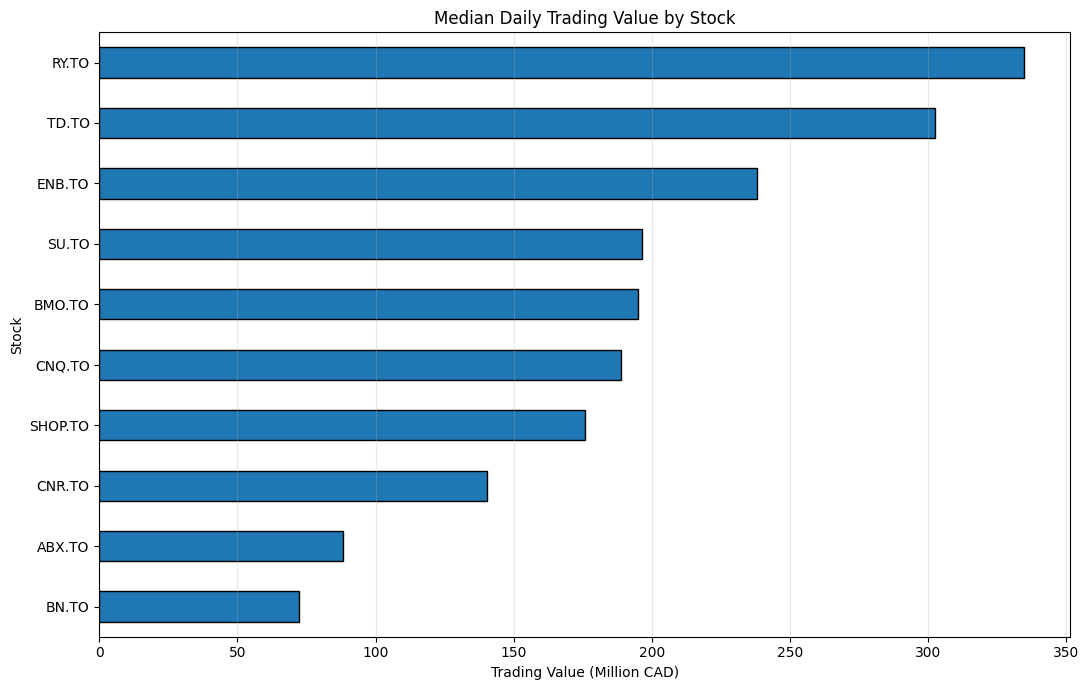

In [29]:
plt.figure(figsize=(11, 7))

trading_summary["Median_Trading_Value"].sort_values().plot(
    kind="barh",
    edgecolor="black"
)

plt.title("Median Daily Trading Value by Stock")
plt.xlabel("Trading Value (Million CAD)")
plt.ylabel("Stock")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

### Stock Trading Activity Analysis

To examine trading activity across the selected Canadian stocks, daily trading value was estimated by multiplying the closing price by the daily trading volume:

`Trading_Value = Close × Volume`

The analysis covered the common period from May 21, 2015, to November 6, 2026.

The results showed considerable differences in trading activity across the selected stocks.

- `RY.TO` recorded the highest median daily trading value at CAD 334.62 million.
- `TD.TO` ranked second, with a median of CAD 302.55 million.
- `ENB.TO` and `SU.TO` also demonstrated relatively high trading activity.
- `BN.TO` recorded the lowest median daily trading value at CAD 72.12 million.

An interesting observation is that `SHOP.TO`, despite achieving the highest cumulative adjusted-price return among the selected stocks, did not record the highest trading value.

This demonstrates that strong historical price performance does not necessarily correspond to the highest trading activity.

Overall, trading value provides an additional perspective on market activity and potential liquidity differences between stocks. However, it is an approximate measure and does not directly represent market capitalization, market depth, or execution liquidity.